# QE011: Teaching a Machine to Steer a Qubit

**Reinforcement learning, rugged control landscapes, and the effective Hamiltonians hidden in fast switching.**

A quantum computer or simulator is controlled by switching fields on and off. The question "*which* switching pattern
moves the system to the state I want?" is hard: the answer depends on the whole history, and the number of patterns
explodes. This exercise attacks it three ways:

* **Part A (one exact answer, Euler-style):** check all 1,048,576 on/off patterns and find the best one.
* **Part B1:** let a reinforcement-learning agent, which knows no physics, discover the best pattern by trial and error,
  then go where brute force cannot reach.
* **Part B2:** map how the "landscape" of all patterns changes with the time allowed: from easy, to rugged and glassy,
  to perfect control.
* **Part B3:** explain why the learned patterns contain rapid flickering. Fast switching creates an *effective*
  Hamiltonian, the same idea that makes a strongly shaken particle stop tunnelling.
* **Animations:** watch the learned protocol steer the qubit on the Bloch sphere, and watch tunnelling switch off.

### Words used in this notebook

| term | meaning |
|---|---|
| **qubit** | a two-level quantum system; its state is a point on the **Bloch sphere** (north pole = \|↑⟩, south pole = \|↓⟩) |
| **Hamiltonian H** | the energy operator; it decides how the state turns on the sphere |
| **field h(t)** | the knob we control; changing it changes the rotation axis |
| **protocol** | the sequence of field values in time. **Bang-bang** = the field is always at one of its two extremes, +4 or −4 |
| **ground state** | the lowest-energy state for a given field |
| **fidelity F** | overlap with the target state: 1 = reached it exactly, 0 = opposite |
| **reinforcement learning (RL)** | learning by trial and error: an **agent** takes **actions**, the **environment** responds, and a **reward** at the end tells how well it did. One attempt = one **episode** |
| **Q-table** | the agent's memory: for every situation and action, an estimate of the final reward |
| **exploration** | taking random actions on purpose to discover new options (probability ε) |
| **local optimum** | a protocol that cannot be improved by flipping any single step, but is not the best overall |
| **glassy landscape** | so many local optima that simple search gets stuck, like a ball on a rugged surface |
| **quantum speed limit** | the shortest time in which the target can be reached perfectly |
| **periodic (Floquet) driving** | shaking a system with a fast periodic field |
| **effective Hamiltonian** | the slower, simpler Hamiltonian that describes a fast-driven system on average |
| **Bessel function J₀** | a standard oscillating mathematical function; here it gives the strength of tunnelling under driving |
| **random seed** | fixes the random draws so every run gives the same numbers |

This notebook needs `numpy`, `scipy`, `pandas` and `matplotlib` (plus `Pillow` for the animations, which comes with
matplotlib). It runs in about two minutes and writes two GIF animations next to itself.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from scipy.linalg import expm
from scipy.special import j0

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
BLUE, ORANGE, GREEN, GRAY, INK, BG = "#2a78d6", "#eb6834", "#1f9e6e", "#8a8984", "#0b0b0b", "#fcfcfb"
rng = np.random.default_rng(11)                                  # random seed

SX = np.array([[0, 1], [1, 0]]) / 2                              # spin operators S = sigma / 2
SY = np.array([[0, -1j], [1j, 0]]) / 2
SZ = np.array([[1, 0], [0, -1]]) / 2
H = lambda h: -SZ - h * SX                                       # qubit in a fixed z-field plus our control field h
ground = lambda h: np.linalg.eigh(H(h))[1][:, 0]
bloch = lambda psi: np.real([np.vdot(psi, 2 * S @ psi) for S in (SX, SY, SZ)])

PSI_START, PSI_TARGET = ground(-2.0), ground(+2.0)               # move from one ground state to another
H_MAX, DT = 4.0, 0.05                                            # bang-bang field values +-4, time step 0.05
fidelity = lambda psi: abs(np.vdot(PSI_TARGET, psi)) ** 2
print("start on the Bloch sphere :", bloch(PSI_START).round(3))
print("target on the Bloch sphere:", bloch(PSI_TARGET).round(3))
print(f"fidelity if we do nothing : {fidelity(PSI_START):.4f}")

start on the Bloch sphere : [-0.894  0.     0.447]
target on the Bloch sphere: [0.894 0.    0.447]
fidelity if we do nothing : 0.2000


## Part A: the best switching pattern

The qubit's Hamiltonian is $H(t) = -S^z - h(t)\,S^x$. It starts in the ground state for $h = -2$, and we want it in the
ground state for $h = +2$. In each time step of length $\delta t = 0.05$ the field is either $+4$ or $-4$.

**Task:** with total time $T = 1.0$ (20 steps, so $2^{20} = 1{,}048{,}576$ possible protocols), find the highest
achievable fidelity $F^\ast$ and report

$$A = \lfloor 10^6 \cdot F^\ast \rfloor .$$

*Check value:* for $T = 0.4$ (8 steps, 256 protocols) the best fidelity is printed below.

**Method.** Grow all protocols at once: after each step, every state splits into two (field −4 or +4). After 20 steps
we hold all 1,048,576 final states in one array and read off their fidelities.

In [2]:
def all_protocols(n_steps, dt=DT):
    U = [expm(-1j * dt * H(-H_MAX)), expm(-1j * dt * H(+H_MAX))]
    states = PSI_START[None, :].astype(complex)
    for _ in range(n_steps):                                     # protocol index: first step = most significant bit
        states = np.stack([states @ U[0].T, states @ U[1].T], axis=1).reshape(-1, 2)
    return np.abs(states @ PSI_TARGET.conj()) ** 2

as_string = lambda index, n: "".join("+" if (index >> (n - 1 - k)) & 1 else "-" for k in range(n))

F8 = all_protocols(8)
print(f"check, T = 0.4: best fidelity {F8.max():.6f}  with protocol {as_string(F8.argmax(), 8)}")

t0 = time.time()
F20 = all_protocols(20)
best20 = F20.argmax()
A = int(np.floor(1e6 * F20.max()))
print(f"T = 1.0: checked {F20.size:,} protocols in {time.time() - t0:.1f} s")
print(f"best fidelity F* = {F20.max():.9f}, reached by {np.sum(F20 > F20.max() - 1e-12)} protocol: {as_string(best20, 20)}")
print(f"\nANSWER  A = {A}")

check, T = 0.4: best fidelity 0.288112  with protocol ++++----
T = 1.0: checked 1,048,576 protocols in 0.1 s
best fidelity F* = 0.576386671, reached by 1 protocol: +++++++-+-+-+-------

ANSWER  A = 576386


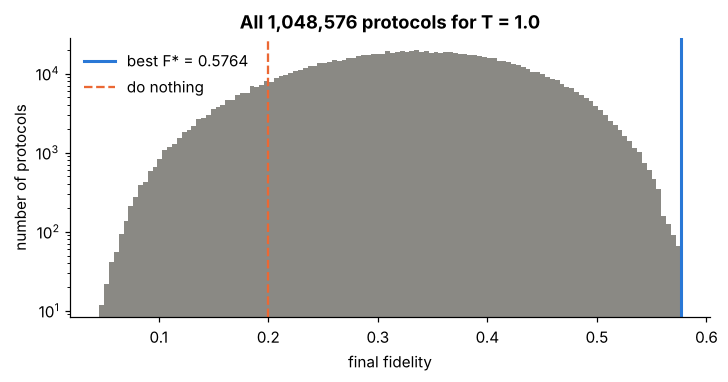

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.3))
ax.hist(F20, bins=120, color=GRAY)
ax.axvline(F20.max(), color=BLUE, lw=2, label=f"best F* = {F20.max():.4f}")
ax.axvline(fidelity(PSI_START), color=ORANGE, lw=1.5, ls="--", label="do nothing")
ax.set_yscale("log"); ax.set_xlabel("final fidelity"); ax.set_ylabel("number of protocols")
ax.legend(frameon=False); ax.set_title("All 1,048,576 protocols for T = 1.0"); plt.show()

The winner, `+++++++-+-+-+-------`, has a striking shape: hold +4, then **flicker** rapidly, then hold −4. Part B3
explains the flicker.

## Part B1: a reinforcement-learning agent

The agent knows nothing about qubits. At each time step it sees only *which step it is at* and *which field it used
last*, and chooses the next field. After the last step it receives one number, the fidelity, as its reward.

**Q-learning.** The agent keeps a table $Q(\text{step}, \text{last field}, \text{action})$, its guess of the final reward.
After each episode it walks backwards through its choices and nudges each entry towards what actually followed:
$Q \leftarrow Q + \alpha\,(\text{target} - Q)$, where the target is the reward at the last step and the best $Q$ of the next
step before that. It explores with probability ε, which shrinks over training, and every 20 episodes it replays its best
protocol so far so it does not forget it.

In [4]:
def q_learning(n_steps, episodes, seed, alpha=0.5, replay_every=20):
    r = np.random.default_rng(seed)
    U = [expm(-1j * DT * H(-H_MAX)), expm(-1j * DT * H(+H_MAX))]
    Q = np.zeros((n_steps, 2, 2))                                # (step, last field, action)
    best_F, best_protocol, history = -1.0, None, []
    for ep in range(episodes):
        eps = max(0.02, 1 - ep / (0.7 * episodes))               # exploration shrinks over time
        replay = best_protocol is not None and ep % replay_every == 0
        protocol, last, psi = [], 0, PSI_START.astype(complex)
        for t in range(n_steps):
            if replay:
                a = best_protocol[t]
            elif r.random() < eps:
                a = int(r.integers(2))
            else:
                q = Q[t, last]; a = int(r.choice(np.flatnonzero(q == q.max())))
            protocol.append(a); psi = U[a] @ psi; last = a
        F = fidelity(psi)                                         # the only reward the agent ever sees
        if F > best_F:
            best_F, best_protocol = F, protocol
        target, previous = F, [0] + protocol[:-1]
        for t in reversed(range(n_steps)):                        # backward Q-learning update
            Q[t, previous[t], protocol[t]] += alpha * (target - Q[t, previous[t], protocol[t]])
            target = Q[t, previous[t]].max()
        history.append(best_F)
    return best_F, best_protocol, np.array(history)

t0 = time.time()
runs_T1 = [q_learning(20, 4000, seed) for seed in range(5)]
runs_T3 = [q_learning(60, 5000, seed) for seed in range(3)]
print(f"trained 8 agents in {time.time() - t0:.0f} s")

table = pd.DataFrame(
    {"T = 1.0 (20 steps)": [f"{F20.max():.6f}", *[f"{r_[0]:.6f}" for r_ in runs_T1]],
     "T = 3.0 (60 steps)": ["impossible (2^60 ≈ 10^18 protocols)", *[f"{r_[0]:.6f}" for r_ in runs_T3], "", ""]},
    index=["exhaustive search", *[f"agent, seed {s}" for s in range(5)]])
best_T3 = max(runs_T3, key=lambda r_: r_[0])
table

trained 8 agents in 24 s


,T = 1.0 (20 steps),T = 3.0 (60 steps)
exhaustive search,0.576387,impossible (2^60 ≈ 10^18 protocols)
"agent, seed 0",0.576387,0.999959
"agent, seed 1",0.575940,0.999997
"agent, seed 2",0.573621,0.999985
"agent, seed 3",0.575940,
"agent, seed 4",0.575593,


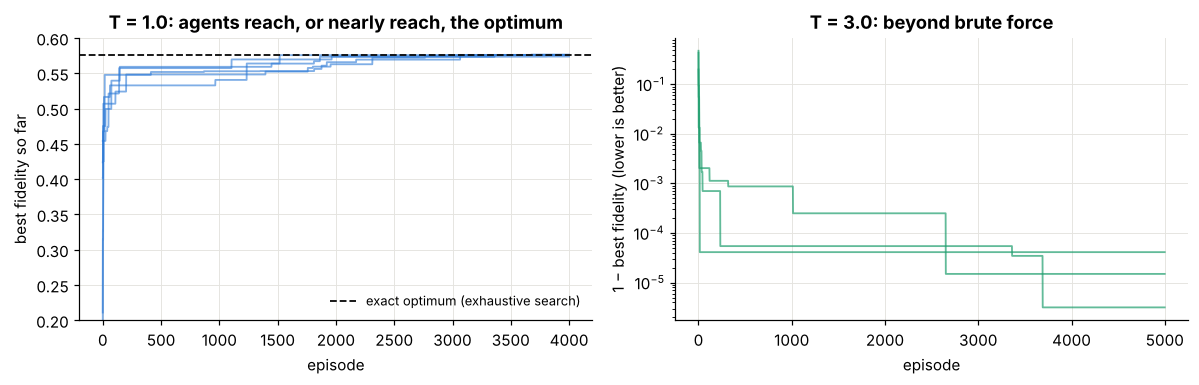

best learned protocol for T = 3.0: -+-++---+-+-+-++--+--+--++++++++----+++----++-+--++---++----  F = 0.999997


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for r_ in runs_T1:
    ax[0].plot(r_[2], color=BLUE, alpha=0.6, lw=1.2)
ax[0].axhline(F20.max(), color=INK, ls="--", lw=1.2, label="exact optimum (exhaustive search)")
ax[0].set_ylim(0.2, 0.6); ax[0].set_title("T = 1.0: agents reach, or nearly reach, the optimum")
for r_ in runs_T3:
    ax[1].plot(1 - r_[2], color=GREEN, alpha=0.7, lw=1.2)
ax[1].set_yscale("log"); ax[1].set_title("T = 3.0: beyond brute force")
ax[1].set_ylabel("1 − best fidelity (lower is better)")
for a in ax:
    a.set_xlabel("episode"); a.grid(color="#e4e3df", lw=0.6)
ax[0].set_ylabel("best fidelity so far"); ax[0].legend(frameon=False, fontsize=8.5, loc="lower right")
plt.tight_layout(); plt.show()
print("best learned protocol for T = 3.0:", "".join("+" if a else "-" for a in best_T3[1]), f" F = {best_T3[0]:.6f}")

## Part B2: phases of the control landscape

Imagine all protocols as points, each with a height equal to its fidelity. A protocol is a **local optimum** if
flipping any single step makes it worse. Count local optima, and near-optimal protocols, as the total time T grows.
To compare times fairly we keep 20 steps and stretch them ($\delta t = T/20$), so every landscape has exactly
$2^{20}$ points and can be checked completely.

In [6]:
neighbours_of = np.arange(2 ** 20)
rows = []
for T in [0.2, 0.4, 0.6, 0.8, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 2.75, 3.0, 3.5]:
    F = all_protocols(20, dt=T / 20)
    flips = np.stack([F[neighbours_of ^ (1 << k)] for k in range(20)])
    local = np.all(F[None] >= flips, axis=0)
    rows.append({"T": T, "best fidelity": F.max(), "local optima": int(local.sum()),
                 "optima within 0.1% of best": int(np.sum(local & (F > 0.999 * F.max())))})
landscape = pd.DataFrame(rows).set_index("T")
landscape.round(6)

,best fidelity,local optima,optima within 0.1% of best
T,,,
0.20,0.223487,2,1
0.40,0.288112,6,1
0.60,0.378566,28,1
0.80,0.477207,185,3
1.00,0.576387,818,5
1.25,0.694790,2914,6
1.50,0.801598,6796,1
1.75,0.891317,12133,1
2.00,0.953190,17984,1


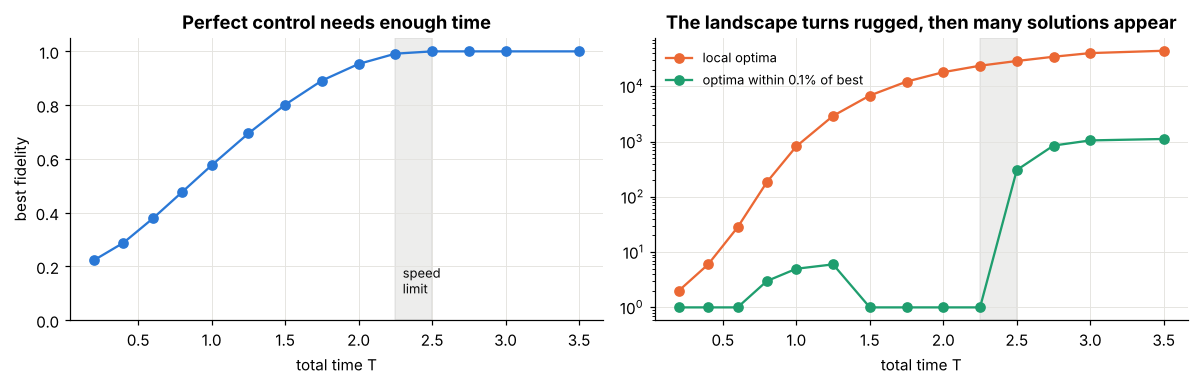

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(landscape.index, landscape["best fidelity"], "o-", color=BLUE)
ax[0].set_xlabel("total time T"); ax[0].set_ylabel("best fidelity"); ax[0].set_ylim(0, 1.05)
ax[0].set_title("Perfect control needs enough time")
ax[1].semilogy(landscape.index, landscape["local optima"], "o-", color=ORANGE, label="local optima")
ax[1].semilogy(landscape.index, landscape["optima within 0.1% of best"], "o-", color=GREEN,
               label="optima within 0.1% of best")
ax[1].set_xlabel("total time T"); ax[1].legend(frameon=False, fontsize=8.5)
ax[1].set_title("The landscape turns rugged, then many solutions appear")
for a in ax:
    a.axvspan(2.25, 2.5, color=GRAY, alpha=0.15)
    a.grid(color="#e4e3df", lw=0.6)
ax[0].text(2.3, 0.1, "speed\nlimit", fontsize=8.5, color=INK)
plt.tight_layout(); plt.show()

Three regimes appear:

* **Short times (T ≲ 0.5):** a handful of local optima. The landscape is simple and any local search finds the best answer.
* **Intermediate times:** thousands of local optima but only one or a few near-best ones. The landscape is *glassy*: simple search gets
  trapped, which is why the agent needs exploration and memory.
* **Beyond the quantum speed limit (T ≈ 2.4):** the target is reached perfectly, and hundreds of different protocols
  do it. Control becomes easy again because there are many ways to win.

## Part B3: why the agent flickers, and effective Hamiltonians

Switching rapidly between $+4$ and $-4$ is, on average, a field of $0$. If the switching is fast enough the qubit only
"feels" the average. Test this on the optimal $T = 1$ protocol: replace its flickering middle by a constant $h = 0$.

In [8]:
def run(fields, dt=DT):
    psi = PSI_START.astype(complex)
    for h in fields:
        psi = expm(-1j * dt * H(h)) @ psi
    return fidelity(psi)

best_fields = [H_MAX if c == "+" else -H_MAX for c in as_string(best20, 20)]
averaged = best_fields.copy(); averaged[7:13] = [0.0] * 6
print(f"optimal bang-bang protocol      : F = {run(best_fields):.5f}")
print(f"flicker replaced by h = 0       : F = {run(averaged):.5f}")

optimal bang-bang protocol      : F = 0.57639
flicker replaced by h = 0       : F = 0.57525


Nearly identical. The agent learned to *synthesise* a field value it was not allowed to use, by switching fast. This
idea, **Floquet engineering**, is how modern quantum simulators create Hamiltonians that nature does not provide.

**A clean example: switching off tunnelling.** A particle tunnelling between two wells is a qubit with
$H = -\Delta\,S^x$. Shake the wells with $A\cos(\omega t)\,S^z$. For fast shaking the effective tunnelling becomes

$$\Delta_\text{eff} = \Delta \cdot J_0(A/\omega),$$

which **vanishes** where the Bessel function $J_0$ crosses zero, at $A/\omega = 2.405$ and $5.520$. Shaking freezes the
particle in place: *coherent destruction of tunnelling*. We check this exactly from the one-period propagator: its
eigenphases give the effective energies (quasi-energies), whose splitting is $\Delta_\text{eff}$.

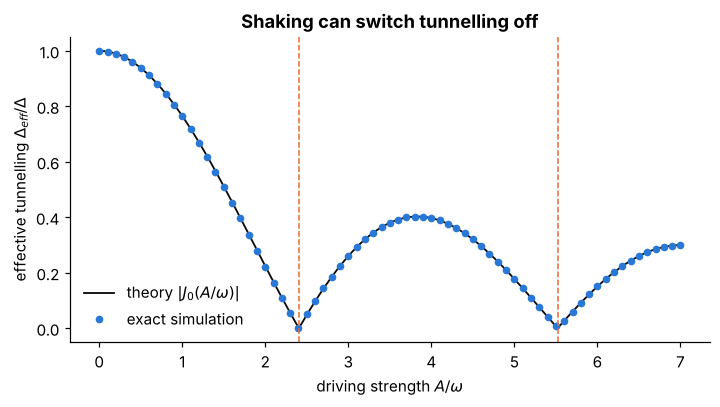

at A/omega = 2.405: effective tunnelling = 0.0015  (undriven: 1.0)


In [9]:
DELTA, OMEGA = 1.0, 10.0

def quasi_energy_splitting(A, steps=200):
    period = 2 * np.pi / OMEGA; dt = period / steps; U = np.eye(2, dtype=complex)
    for k in range(steps):
        t = (k + 0.5) * dt
        U = expm(-1j * dt * (-DELTA * SX + A * np.cos(OMEGA * t) * SZ)) @ U
    eps = np.sort(-np.angle(np.linalg.eigvals(U)) / period)
    d = abs(eps[1] - eps[0])
    return min(d, OMEGA - d)

ratios = np.linspace(0, 7, 71)
split = [quasi_energy_splitting(r_ * OMEGA) for r_ in ratios]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
xs = np.linspace(0, 7, 400)
ax.plot(xs, np.abs(j0(xs)), color=INK, lw=1.2, label=r"theory $|J_0(A/\omega)|$")
ax.plot(ratios, split, "o", ms=4, color=BLUE, label="exact simulation")
for z in (2.405, 5.520):
    ax.axvline(z, color=ORANGE, ls="--", lw=1)
ax.set_xlabel(r"driving strength $A/\omega$"); ax.set_ylabel(r"effective tunnelling $\Delta_{eff}/\Delta$")
ax.legend(frameon=False); ax.set_title("Shaking can switch tunnelling off"); plt.show()
print(f"at A/omega = 2.405: effective tunnelling = {quasi_energy_splitting(2.405 * OMEGA):.4f}  (undriven: 1.0)")

## Animations

**1. The learned protocol at work.** The best $T = 3$ protocol found by the agent steers the qubit from the start
(orange) to the target (green). Each switch of the field changes the rotation axis, so the path is a chain of arcs.

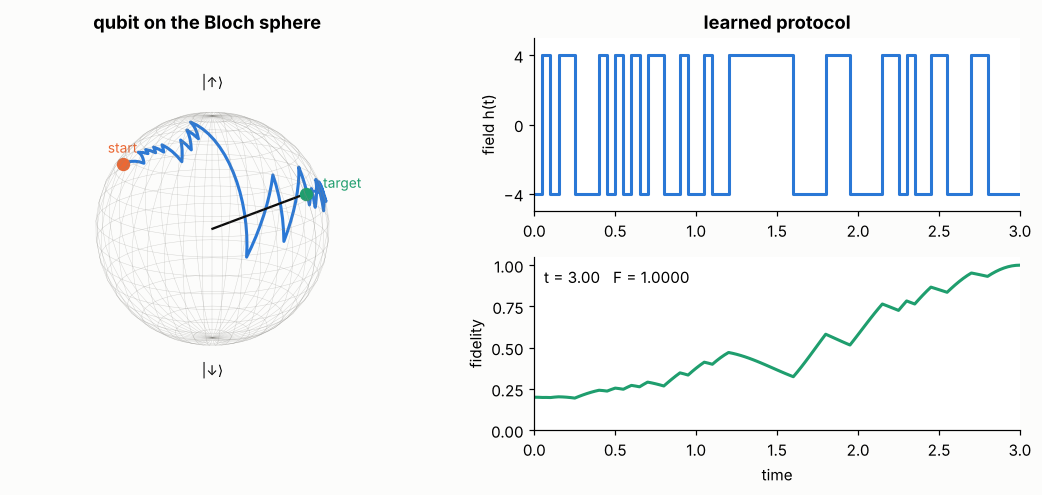

saved qe011_bloch_control.gif (42 s); the final frame is shown above


In [10]:
def bloch_animation(protocol, filename, sub=2, fps=15):
    fields = np.array([-H_MAX, H_MAX])[protocol]
    U = [expm(-1j * DT / sub * H(h)) for h in (-H_MAX, H_MAX)]
    psi = PSI_START.astype(complex); path = [bloch(psi)]; fid = [fidelity(psi)]
    for a in protocol:
        for _ in range(sub):
            psi = U[a] @ psi; path.append(bloch(psi)); fid.append(fidelity(psi))
    path, fid = np.array(path), np.array(fid); tt = np.arange(len(fid)) * DT / sub
    steps = np.arange(len(protocol)) * DT

    fig = plt.figure(figsize=(10, 4.6), facecolor=BG)
    ax3 = fig.add_subplot(1, 2, 1, projection="3d", facecolor=BG)
    axh, axf = fig.add_subplot(2, 2, 2), fig.add_subplot(2, 2, 4)
    u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
    ax3.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v), color=GRAY, lw=0.3, alpha=0.35)
    for vec, col, lab in [(bloch(PSI_START), ORANGE, "start"), (bloch(PSI_TARGET), GREEN, "target")]:
        ax3.scatter(*vec, color=col, s=60, depthshade=False); ax3.text(*(vec * 1.18), lab, color=col, fontsize=9)
    ax3.text(0, 0, 1.25, "|↑⟩", ha="center", fontsize=9); ax3.text(0, 0, -1.35, "|↓⟩", ha="center", fontsize=9)
    line, = ax3.plot([], [], [], color=BLUE, lw=2)
    arrow, = ax3.plot([], [], [], color=INK, lw=1.5)
    ax3.set_xlim(-1, 1); ax3.set_ylim(-1, 1); ax3.set_zlim(-1, 1); ax3.set_box_aspect((1, 1, 1)); ax3.axis("off")
    ax3.view_init(elev=18, azim=-60); ax3.set_title("qubit on the Bloch sphere")
    axh.step(np.r_[steps, steps[-1] + DT], np.r_[fields, fields[-1]], where="post", color=GRAY, lw=1)
    hline, = axh.step([], [], where="post", color=BLUE, lw=2)
    axh.set_ylim(-5, 5); axh.set_xlim(0, len(protocol) * DT); axh.set_yticks([-4, 0, 4])
    axh.set_ylabel("field h(t)"); axh.set_title("learned protocol")
    axf.plot(tt, fid, color=GRAY, lw=1); fline, = axf.plot([], [], color=GREEN, lw=2)
    axf.set_ylim(0, 1.05); axf.set_xlim(0, tt[-1]); axf.set_xlabel("time"); axf.set_ylabel("fidelity")
    label = axf.text(0.02, 0.85, "", transform=axf.transAxes)
    fig.tight_layout()

    def draw(k):
        line.set_data_3d(path[:k + 1, 0], path[:k + 1, 1], path[:k + 1, 2])
        arrow.set_data_3d([0, path[k, 0]], [0, path[k, 1]], [0, path[k, 2]])
        n = min(k // sub, len(protocol) - 1)
        hline.set_data(np.r_[steps[:n + 1], steps[n] + DT], np.r_[fields[:n + 1], fields[n]])
        fline.set_data(tt[:k + 1], fid[:k + 1]); label.set_text(f"t = {tt[k]:.2f}   F = {fid[k]:.4f}")
        return line, arrow, hline, fline, label

    frames = list(range(len(fid))) + [len(fid) - 1] * fps                    # hold the last frame for 1 s
    animation.FuncAnimation(fig, draw, frames=frames, blit=False).save(
        filename, writer=animation.PillowWriter(fps=fps), dpi=90, savefig_kwargs={"facecolor": BG})
    draw(len(fid) - 1)
    plt.show()

t0 = time.time()
bloch_animation(best_T3[1], "qe011_bloch_control.gif")
print(f"saved qe011_bloch_control.gif ({time.time() - t0:.0f} s); the final frame is shown above")

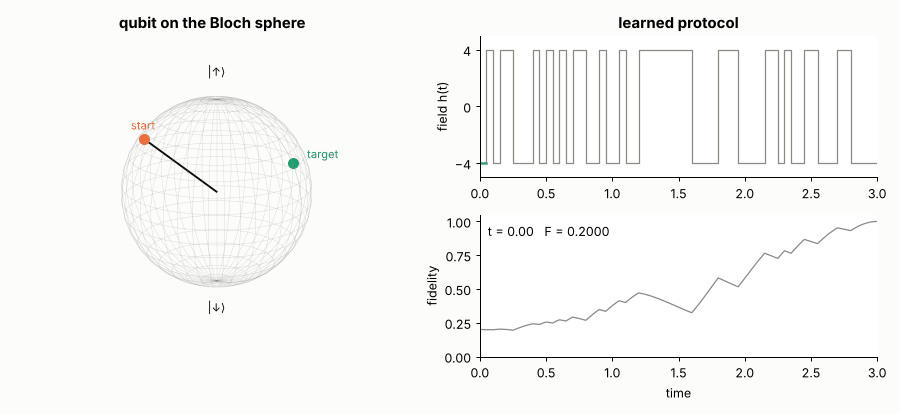

**2. Shaking switches tunnelling off.** Left: an undriven particle tunnels back and forth between the two wells.
Right: the same particle, shaken at $A/\omega = 2.405$, stays where it started.

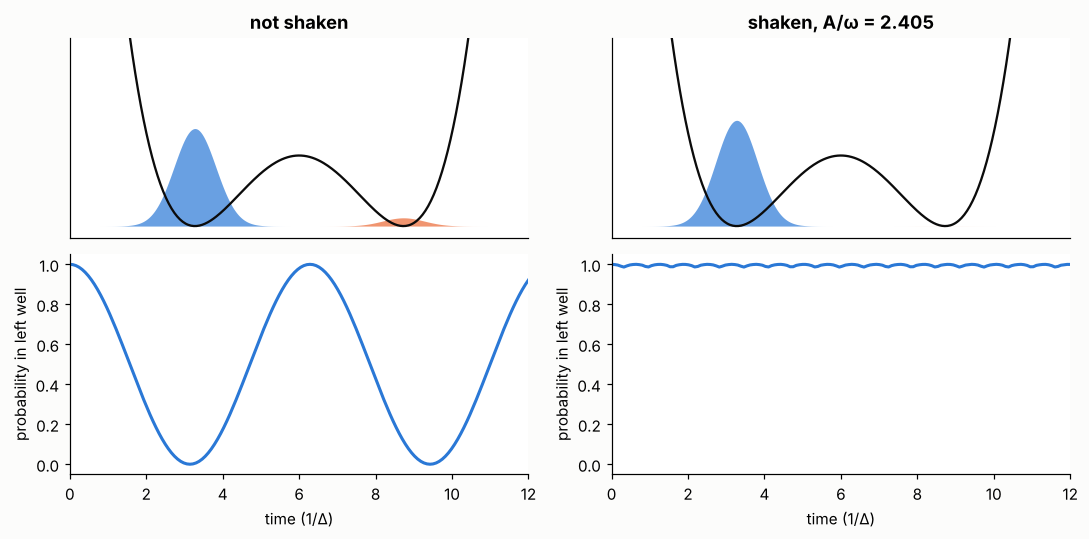

saved qe011_tunnelling.gif (45 s); lowest left-well probability: not shaken: 0.000, shaken, A/ω = 2.405: 0.986


In [11]:
def tunnelling_animation(filename, t_max=12.0, frames=150, fps=15):
    t = np.linspace(0, t_max, frames); dt = t[1] - t[0]; sub = 40
    out = {}
    for name, A in [("not shaken", 0.0), ("shaken, A/ω = 2.405", 2.405 * OMEGA)]:
        psi = np.array([1, 0], complex); p_left = [1.0]; clock = 0.0
        for _ in range(frames - 1):
            for _ in range(sub):
                h = dt / sub
                psi = expm(-1j * h * (-DELTA * SX + A * np.cos(OMEGA * (clock + h / 2)) * SZ)) @ psi
                clock += h
            p_left.append(abs(psi[0]) ** 2)
        out[name] = np.array(p_left)

    fig, axes = plt.subplots(2, 2, figsize=(10, 5), gridspec_kw={"height_ratios": [1, 1.1]}, facecolor=BG)
    x = np.linspace(-2, 2, 300); well = 0.6 * (x ** 2 - 1) ** 2
    artists = []
    for col, (name, p) in enumerate(out.items()):
        aw, ap = axes[0, col], axes[1, col]
        aw.plot(x, well, color=INK, lw=1.5); aw.set_ylim(-0.1, 1.6); aw.set_xticks([]); aw.set_yticks([])
        aw.set_title(name)
        ap.plot(t, p, color=GRAY, lw=1); pl, = ap.plot([], [], color=BLUE, lw=2)
        ap.set_ylim(-0.05, 1.05); ap.set_xlim(0, t_max); ap.set_xlabel("time (1/Δ)")
        ap.set_ylabel("probability in left well")
        artists.append((aw, ap, pl, p))
    fig.tight_layout()
    blobs = [None, None]

    def draw(k):
        for i, (aw, ap, pl, p) in enumerate(artists):
            if blobs[i] is not None:
                for b in blobs[i]:
                    b.remove()
            gl = p[k] * np.exp(-((x + 1) ** 2) / 0.08); gr = (1 - p[k]) * np.exp(-((x - 1) ** 2) / 0.08)
            blobs[i] = [aw.fill_between(x, 0, 0.9 * gl, color=BLUE, alpha=0.7, lw=0),
                        aw.fill_between(x, 0, 0.9 * gr, color=ORANGE, alpha=0.7, lw=0)]
            pl.set_data(t[:k + 1], p[:k + 1])
        return []

    animation.FuncAnimation(fig, draw, frames=list(range(frames)) + [frames - 1] * fps).save(
        filename, writer=animation.PillowWriter(fps=fps), dpi=80, savefig_kwargs={"facecolor": BG})
    draw(frames - 1); plt.show()
    return out

t0 = time.time()
tunnel = tunnelling_animation("qe011_tunnelling.gif")
print(f"saved qe011_tunnelling.gif ({time.time() - t0:.0f} s); lowest left-well probability: "
      + ", ".join(f"{k}: {v.min():.3f}" for k, v in tunnel.items()))

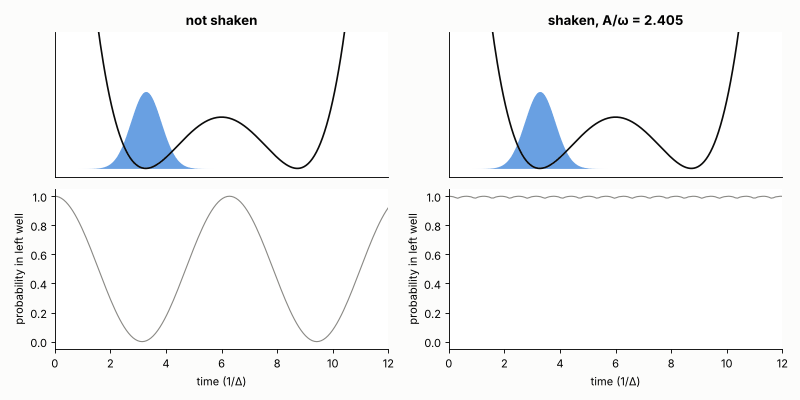

## Conclusions

1. **Exhaustive search gives the exact answer for short times.** For $T = 1$ the best of 1,048,576 bang-bang protocols
   reaches $F^\ast = 0.576387$, so $A = 576386$.
2. **A physics-blind agent finds it too.** Using only the final fidelity as feedback, one of five Q-learning agents
   rediscovers the exact optimum and the other four end within 0.5% of it. At $T = 3$, where $2^{60}$ protocols rule out brute force, it reaches fidelities above 0.9999.
3. **The control landscape has phases.** It goes from simple (few optima), to glassy (thousands of traps), to
   controllable (many perfect solutions beyond the quantum speed limit).
4. **Fast switching builds effective Hamiltonians.** The learned flicker acts as a zero field, and periodic shaking can
   switch tunnelling off exactly where $J_0(A/\omega) = 0$.

**Try it yourself:** allow three field values (−4, 0, +4), give the agent the qubit's measured state as extra input,
add noise to the fields, or make the target a two-qubit entangled state.

### Further reading

* M. Bukov, A. G. R. Day, D. Sels, P. Weinberg, A. Polkovnikov, P. Mehta, *Reinforcement learning in different phases
  of quantum control*, Phys. Rev. X 8, 031086 (2018).
* M. Bukov, L. D'Alessio, A. Polkovnikov, *Universal high-frequency behavior of periodically driven systems: from
  dynamical stabilization to Floquet engineering*, Adv. Phys. 64, 139 (2015).
* F. Grossmann, T. Dittrich, P. Jung, P. Hänggi, *Coherent destruction of tunneling*, Phys. Rev. Lett. 67, 516 (1991).
* R. S. Sutton, A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed., MIT Press (2018).